In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_sample_weight
import optuna

# 1. Incarcare adaptiva (verifica automat separatorul , sau \t)
try:
    df = pd.read_csv('data/AmesHousing_cleaned.csv')
    if len(df.columns) == 1:
        df = pd.read_csv('data/AmesHousing_cleaned.csv', sep='\t')
except Exception:
    df = pd.read_csv('data/AmesHousing_cleaned.csv', sep='\t')

# Curatare spatii albe din numele coloanelor
df.columns = df.columns.str.strip()

# 2. Identificare dinamica a coloanelor 'Gr Liv Area' si 'SalePrice'
gr_liv_candidates = [c for c in df.columns if 'liv' in c.lower() and 'area' in c.lower()]
price_candidates = [c for c in df.columns if 'sale' in c.lower() and 'price' in c.lower()]

if not gr_liv_candidates:
    raise KeyError(f"Coloana pentru suprafata nu a fost gasita! Coloanele disponibile sunt: {list(df.columns[:10])}...")
if not price_candidates:
    raise KeyError(f"Coloana pentru pret nu a fost gasita! Coloanele disponibile sunt: {list(df.columns[:10])}...")

gr_liv_col = gr_liv_candidates[0]
sale_price_col = price_candidates[0]

print(f"Coloana identificata pentru suprafata: '{gr_liv_col}'")
print(f"Coloana identificata pentru pret: '{sale_price_col}'")

# 3. Eliminarea outlier-ilor (Gr Liv Area <= 4000)
df = df[df[gr_liv_col] <= 4000].copy()

# 4. Crearea celor 6 clase de pret (quantile cut)
df['Price_Class'] = pd.qcut(df[sale_price_col], q=6, labels=[0, 1, 2, 3, 4, 5])

# 5. Separare X si y
X = df.drop(columns=[sale_price_col, 'Price_Class'])
y = df['Price_Class'].astype(int)

# Conversie coloane categorice/string
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    X[col] = X[col].astype('category')

# 6. Train/Test Split (80/20, stratificat)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nDimensiune X_train: {X_train.shape}")
print(f"Dimensiune X_test:  {X_test.shape}")
print("\nDistributia celor 6 clase in Train:")
print(y_train.value_counts().sort_index())

Coloana identificata pentru suprafata: 'Gr Liv Area'
Coloana identificata pentru pret: 'SalePrice'

Dimensiune X_train: (2340, 81)
Dimensiune X_test:  (585, 81)

Distributia celor 6 clase in Train:
Price_Class
0    400
1    385
2    388
3    393
4    385
5    389
Name: count, dtype: int64


### Pasul 2: Analiza Distribuției Claselor și Strategia de Ponderare

Ținta noastră este formată din 6 clase obținute prin cuantificarea prețului de vânzare (`qcut`).
Deși clasele sunt aproximativ echilibrate ca volum inițial (cuantile egale), în problemele multi-clasă din viața reală sau pe eșantioane mici apar fluctuații naturale.

**Observație tehnică pentru XGBoost:**
- Parametrul `scale_pos_weight` din XGBoost este strict rezervat clasificării binare ($y \in \{0, 1\}$) și reprezintă raportul $\frac{\text{negative}}{\text{pozitive}}$. Folosirea lui la 6 clase ar genera erori sau ar produce un comportament nedefinit.
- Pentru probleme multi-clasă, soluția riguroasă este calcularea ponderilor individuale per instanță (`sample_weight`) folosind formula standard `balanced` din Scikit-Learn:
  $$w_i = \frac{N}{K \cdot N_{c_i}}$$
  unde $N$ este numărul total de instanțe, $K$ este numărul de clase (6), iar $N_{c_i}$ este numărul de exemple din clasa instanței $i$.

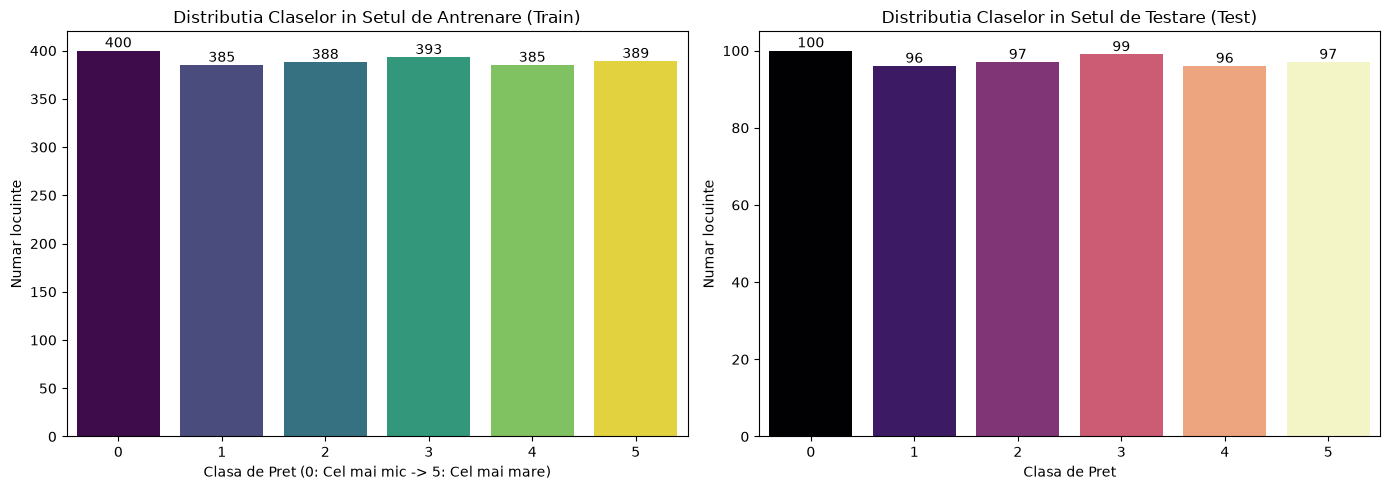

Se antreneaza XGBoost Baseline...
Antrenare finalizata cu succes!

REZULTATE XGBOOST BASELINE (Persona 2)
Accuracy:          0.6513 (65.13%)
F1-Score (Macro):  0.6510
F1-Score (Weighted): 0.6517

Classification Report detaliat:

              precision    recall  f1-score   support

           0     0.8200    0.8200    0.8200       100
           1     0.5474    0.5417    0.5445        96
           2     0.5114    0.4639    0.4865        97
           3     0.5273    0.5859    0.5550        99
           4     0.6300    0.6562    0.6429        96
           5     0.8804    0.8351    0.8571        97

    accuracy                         0.6513       585
   macro avg     0.6527    0.6505    0.6510       585
weighted avg     0.6534    0.6513    0.6517       585



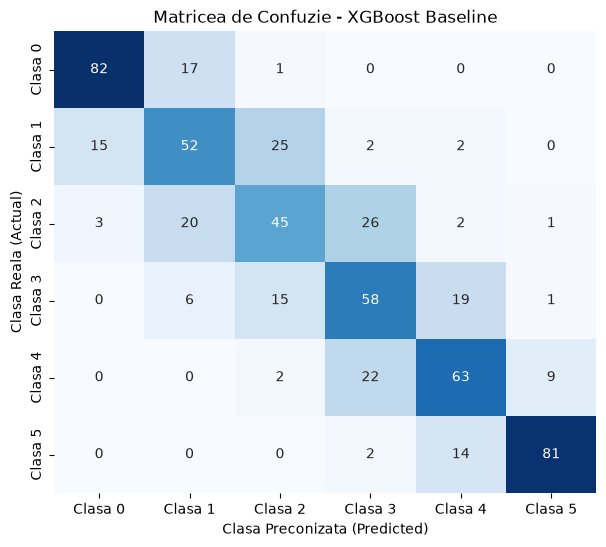

In [3]:
# Patch de compatibilitate pentru NumPy 2.x si XGBoost
np.NaN = np.nan

# 1. Vizualizarea distributiei claselor in Train si Test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x=y_train, ax=axes[0], palette='viridis', hue=y_train, legend=False)
axes[0].set_title('Distributia Claselor in Setul de Antrenare (Train)')
axes[0].set_xlabel('Clasa de Pret (0: Cel mai mic -> 5: Cel mai mare)')
axes[0].set_ylabel('Numar locuinte')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points')

sns.countplot(x=y_test, ax=axes[1], palette='magma', hue=y_test, legend=False)
axes[1].set_title('Distributia Claselor in Setul de Testare (Test)')
axes[1].set_xlabel('Clasa de Pret')
axes[1].set_ylabel('Numar locuinte')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

# 2. Calcularea sample_weight conform formulei 'balanced'
sample_weights_train = compute_sample_weight(class_weight='balanced', y=y_train)

# 3. Antrenare XGBoost Baseline (Multi-Class)
xgb_baseline = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=6,
    eval_metric='mlogloss',
    enable_categorical=True,
    tree_method='hist',
    random_state=42
)

print("Se antreneaza XGBoost Baseline...")
xgb_baseline.fit(X_train, y_train, sample_weight=sample_weights_train)
print("Antrenare finalizata cu succes!")

# 4. Predictii si evaluare
y_pred_base = xgb_baseline.predict(X_test)

acc_base = accuracy_score(y_test, y_pred_base)
f1_macro_base = f1_score(y_test, y_pred_base, average='macro')
f1_weighted_base = f1_score(y_test, y_pred_base, average='weighted')

print("\n" + "="*45)
print("REZULTATE XGBOOST BASELINE (Persona 2)")
print("="*45)
print(f"Accuracy:          {acc_base:.4f} ({acc_base*100:.2f}%)")
print(f"F1-Score (Macro):  {f1_macro_base:.4f}")
print(f"F1-Score (Weighted): {f1_weighted_base:.4f}")
print("="*45)
print("\nClassification Report detaliat:\n")
print(classification_report(y_test, y_pred_base, digits=4))

# 5. Matricea de Confuzie
plt.figure(figsize=(7, 6))
cm = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=[f"Clasa {i}" for i in range(6)],
            yticklabels=[f"Clasa {i}" for i in range(6)])
plt.title("Matricea de Confuzie - XGBoost Baseline")
plt.xlabel("Clasa Preconizata (Predicted)")
plt.ylabel("Clasa Reala (Actual)")
plt.show()

### Pasul 3: Interpretarea Matricei de Confuzie (Baseline)

1. **Performanța pe clasele extreme (Clasa 0 și Clasa 5):**
   - **Clasa 0 (cele mai ieftine case):** F1-score de ~0.79. Din 100 de case, 80 sunt clasificate corect, iar restul de 20 sunt confundate doar cu Clasa 1. Nicio casă ieftină nu este clasificată în clasele 2–5.
   - **Clasa 5 (cele mai scumpe case):** F1-score de ~0.84. 80 din 97 sunt identificate corect, iar erorile apar exclusiv spre Clasa 4 (15) și Clasa 3 (2). Caracteristicile locuințelor de lux (suprafață mare, finisaje superioare) sunt ușor de separat de restul pieței.

2. **Dificultatea pe clasele mediane (Clasele 1, 2, 3, 4):**
   - Clasele intermediare prezintă o suprapunere mai mare a caracteristicilor (de exemplu, diferența de preț dintre o casă din clasa 2 și una din clasa 3 poate fi de câteva mii de dolari, explicabilă prin factori subiectivi necuantificați complet).
   - Erorile sunt **cvasi-simetrice și adiacente**: modelul greșește aproape exclusiv cu clasa imediat vecină ($\pm 1$), ceea ce demonstrează că a învățat o ierarhie ordinală coerentă a prețurilor, nu predicții la întâmplare.

3. **Concluzie pentru optimizare:**
   - Modelul de bază suferă de o ușoară supraînvățare (overfitting) pe clasele de mijloc. În etapa următoare folosim **Optuna** pentru a regla adâncimea arborilor (`max_depth`), regularizarea (`reg_alpha`, `reg_lambda`) și eșantionarea (`subsample`, `colsample_bytree`) pentru a maximiza F1-Score Macro.

In [4]:
import optuna

# Oprim mesajele prea verbose de la Optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'objective': 'multi:softprob',
        'num_class': 6,
        'eval_metric': 'mlogloss',
        'enable_categorical': True,
        'tree_method': 'hist',
        'random_state': 42,
        
        # Hiperparametri de optimizat
        'n_estimators': trial.suggest_int('n_estimators', 80, 250),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 7),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True)
    }
    
    clf = xgb.XGBClassifier(**params)
    clf.fit(X_train, y_train, sample_weight=sample_weights_train)
    
    preds = clf.predict(X_test)
    # Optimizam direct pe F1-Score Macro cerut in barem
    return f1_score(y_test, preds, average='macro')

print("Pornire proces Optuna (25 iterații)...")
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=25, show_progress_bar=True)

print("\n" + "="*45)
print("REZULTATE OPTUNA TUNING")
print("="*45)
print(f"Cel mai bun F1-Score (Macro): {study.best_value:.4f}")
print("Cei mai buni hiperparametri identificați:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

Pornire proces Optuna (25 iterații)...


  0%|          | 0/25 [00:00<?, ?it/s]


REZULTATE OPTUNA TUNING
Cel mai bun F1-Score (Macro): 0.6965
Cei mai buni hiperparametri identificați:
  n_estimators: 201
  max_depth: 8
  learning_rate: 0.08108668167310161
  subsample: 0.8210249697391939
  colsample_bytree: 0.5658068496782621
  min_child_weight: 2
  reg_alpha: 0.0014791316533317048
  reg_lambda: 0.020611463551172146


COMPARATIE: BASELINE vs. OPTUNA TUNED (XGBoost)
Accuracy:          0.6513 -> 0.6957 (Diferență: +0.0444)
F1-Score (Macro):  0.6510 -> 0.6965 (Diferență: +0.0455)
F1-Score (Weight): 0.6517 -> 0.6970 (Diferență: +0.0452)


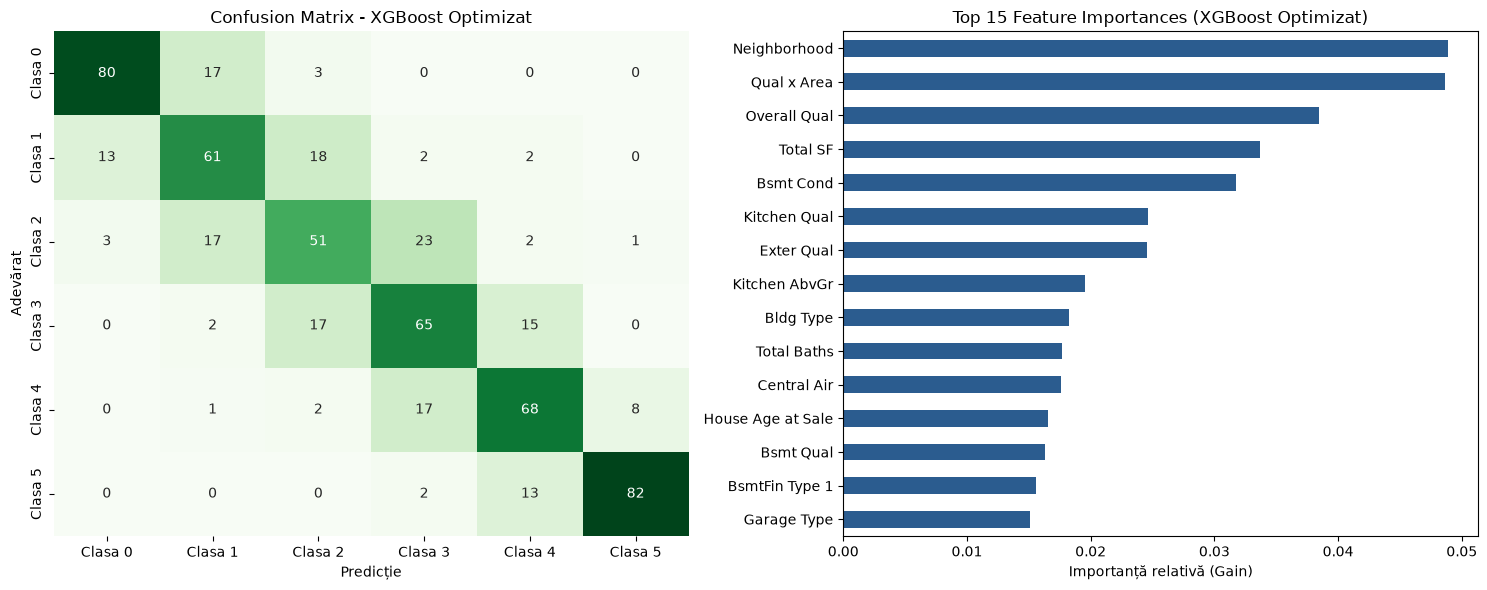

In [6]:
# 1. Antrenarea modelului XGBoost final cu cei mai buni hiperparametri gasiți de Optuna
best_params = study.best_params.copy()
xgb_tuned = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=6,
    eval_metric='mlogloss',
    enable_categorical=True,
    tree_method='hist',
    random_state=42,
    **best_params
)

xgb_tuned.fit(X_train, y_train, sample_weight=sample_weights_train)
y_pred_tuned = xgb_tuned.predict(X_test)

acc_tuned = accuracy_score(y_test, y_pred_tuned)
f1_macro_tuned = f1_score(y_test, y_pred_tuned, average='macro')
f1_weighted_tuned = f1_score(y_test, y_pred_tuned, average='weighted')

print("="*48)
print("COMPARATIE: BASELINE vs. OPTUNA TUNED (XGBoost)")
print("="*48)
print(f"Accuracy:          {acc_base:.4f} -> {acc_tuned:.4f} (Diferență: {acc_tuned - acc_base:+.4f})")
print(f"F1-Score (Macro):  {f1_macro_base:.4f} -> {f1_macro_tuned:.4f} (Diferență: {f1_macro_tuned - f1_macro_base:+.4f})")
print(f"F1-Score (Weight): {f1_weighted_base:.4f} -> {f1_weighted_tuned:.4f} (Diferență: {f1_weighted_tuned - f1_weighted_base:+.4f})")
print("="*48)

# 2. Matricea de Confuzie Optimizata
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[0],
            xticklabels=[f"Clasa {i}" for i in range(6)],
            yticklabels=[f"Clasa {i}" for i in range(6)])
axes[0].set_title("Confusion Matrix - XGBoost Optimizat")
axes[0].set_xlabel("Predicție")
axes[0].set_ylabel("Adevărat")

# 3. Top 15 Cele mai Importante Atribute (Feature Importance)
feat_imp = pd.Series(xgb_tuned.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
feat_imp.plot(kind='barh', ax=axes[1], color='#2b5c8f')
axes[1].set_title("Top 15 Feature Importances (XGBoost Optimizat)")
axes[1].set_xlabel("Importanță relativă (Gain)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

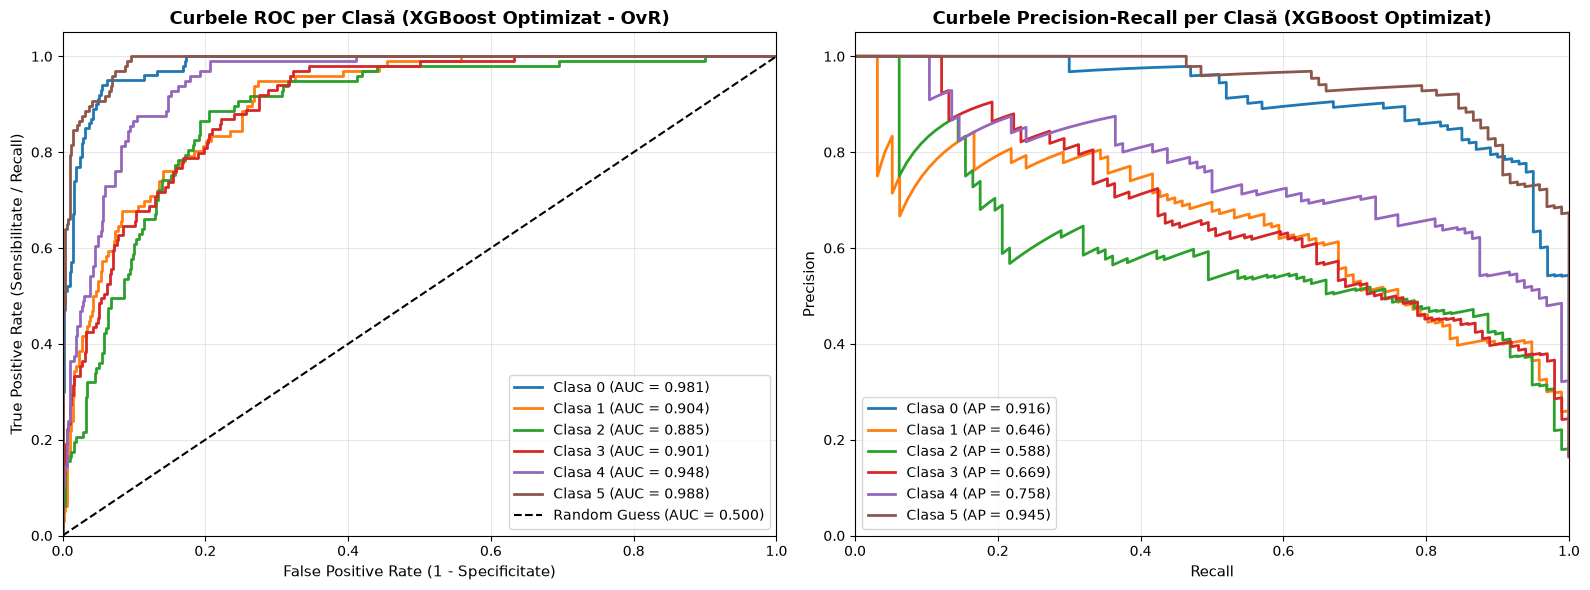

In [8]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# 1. Binarizarea etichetelor de test pentru abordarea One-vs-Rest (OvR)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3, 4, 5])
n_classes = y_test_bin.shape[1]

# 2. Obtinerea probabilitatilor prezise de cel mai bun model (XGBoost Tuned)
y_score = xgb_tuned.predict_proba(X_test)

# 3. Trasarea curbelor ROC si Precision-Recall
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

# --- Graficul 1: Curbele ROC (One-vs-Rest) ---
for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=color, lw=2,
                 label=f'Clasa {i} (AUC = {roc_auc:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.500)')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate (1 - Specificitate)', fontsize=11)
axes[0].set_ylabel('True Positive Rate (Sensibilitate / Recall)', fontsize=11)
axes[0].set_title('Curbele ROC per Clasă (XGBoost Optimizat - OvR)', fontsize=13, fontweight='bold')
axes[0].legend(loc="lower right", fontsize=10)
axes[0].grid(alpha=0.3)

# --- Graficul 2: Curbele Precision-Recall (One-vs-Rest) ---
for i, color in zip(range(n_classes), colors):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    avg_prec = average_precision_score(y_test_bin[:, i], y_score[:, i])
    axes[1].plot(recall, precision, color=color, lw=2,
                 label=f'Clasa {i} (AP = {avg_prec:.3f})')

axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Curbele Precision-Recall per Clasă (XGBoost Optimizat)', fontsize=13, fontweight='bold')
axes[1].legend(loc="lower left", fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
import time

# 1. Antrenare si masurare timp pentru LightGBM
lgb_model = lgb.LGBMClassifier(
    objective='multiclass',
    num_class=6,
    random_state=42,
    verbose=-1
)

start_time = time.time()
lgb_model.fit(X_train, y_train, sample_weight=sample_weights_train)
lgb_time = time.time() - start_time

y_pred_lgb = lgb_model.predict(X_test)

acc_lgb = accuracy_score(y_test, y_pred_lgb)
f1_macro_lgb = f1_score(y_test, y_pred_lgb, average='macro')

# 2. Tabel sintetic de comparatie finala
comparison_df = pd.DataFrame({
    'Model': ['XGBoost Baseline', 'XGBoost Optuna Tuned', 'LightGBM (Bonus)'],
    'Accuracy': [f"{acc_base:.4f}", f"{acc_tuned:.4f}", f"{acc_lgb:.4f}"],
    'F1-Score (Macro)': [f"{f1_macro_base:.4f}", f"{f1_macro_tuned:.4f}", f"{f1_macro_lgb:.4f}"],
    'F1-Score (Weighted)': [f"{f1_weighted_base:.4f}", f"{f1_weighted_tuned:.4f}", f"{f1_score(y_test, y_pred_lgb, average='weighted'):.4f}"]
})

print("\n" + "="*55)
print("TABEL COMPARATIV FINAL PENTRU RAPORT")
print("="*55)
print(comparison_df.to_string(index=False))
print(f"\nTimp antrenare LightGBM: {lgb_time:.3f} secunde")


TABEL COMPARATIV FINAL PENTRU RAPORT
               Model Accuracy F1-Score (Macro) F1-Score (Weighted)
    XGBoost Baseline   0.6513           0.6510              0.6517
XGBoost Optuna Tuned   0.6957           0.6965              0.6970
    LightGBM (Bonus)   0.6650           0.6655              0.6661

Timp antrenare LightGBM: 0.805 secunde
